# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

## Preliminares

In [1]:
import pandas as pd

from src.modeling import (
    cargar_datos_clean, filtrar_pares_restantes, separar_train_test,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots, top_correlaciones_objetivo,
    rankear_variables
)

# Cargar fichero de precios
simbolo_objetivo = "EURUSD"
df_clean = cargar_datos_clean(simbolo=simbolo_objetivo)

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 912 entries, 2008-05-05 to 2026-11-09
Columns: 128 entries, EURUSD_intra_weekly to VIX_vel_50d_yeo
dtypes: float64(128)
memory usage: 919.1 KB


In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

## Analisis de variables

In [3]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "skew"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
EURUSD_return_skew_lag1,912.0,-0.017737,0.138445,-0.359504,-0.111002,-0.021812,0.068107,0.416551
GBPUSD_return_skew_lag1,912.0,0.042757,0.144356,-0.302718,-0.072245,0.032943,0.165015,0.413965
USDJPY_return_skew_lag1,912.0,-0.078586,0.150736,-0.383015,-0.198876,-0.093845,0.014336,0.348251
USDCAD_return_skew_lag1,912.0,0.031367,0.128529,-0.263989,-0.064607,0.031233,0.131573,0.316744
USDCHF_return_skew_lag1,912.0,-0.035037,0.166713,-0.415181,-0.144382,-0.004001,0.098474,0.309857
AUDUSD_return_skew_lag1,912.0,-0.059186,0.101850,-0.313033,-0.130531,-0.063534,0.014559,0.195088
Gold_return_skew_lag1,912.0,-0.052391,0.170065,-0.448083,-0.165139,-0.070164,0.050368,0.409314
Oil_return_skew_lag1,912.0,-0.095897,0.115067,-0.520634,-0.170512,-0.092390,-0.016009,0.190037
SPY_return_skew_lag1,912.0,-0.092559,0.150117,-0.416500,-0.195052,-0.133413,0.023676,0.293453
EURUSD_gap_skew_lag1,912.0,-0.109281,0.275113,-0.746203,-0.325891,-0.073259,0.095780,0.633967


In [4]:
# Asimetrias general
mostrar_asimetrias(df_clean)

VIX_level                           2.474253
USDCAD_std_lag1_log                 1.586441
STLFSI_vel_50d                      0.996643
USDCHF_std_lag1_log                 0.993569
Oil_vol_directional_lag1_log        0.967022
AUDUSD_gap_skew_lag1                0.891184
GBPUSD_std_lag1_log                 0.873957
Real_yield_vel_50d                  0.814570
Oil_std_lag1_log                    0.643036
EURUSD_open_gap_zscore_yeo          0.610313
AUDUSD_vol_directional_lag1_log     0.564015
AUDUSD_sma15_pct_diff_sma50_lag1    0.542136
SPY_return_skew_lag1                0.497819
GBPUSD_vol_directional_lag1_log     0.456852
USDJPY_return_skew_lag1             0.434759
USDJPY_sma15_pct_diff_sma50_lag1    0.420560
AUDUSD_std_lag1_log                 0.411459
SPY_acceleration_zscore_lag1        0.397352
USDJPY_yield_spread_zscore_skew     0.382140
SPY_vol_directional_lag1_log        0.368063
Gold_return_skew_lag1               0.366121
USDCHF_yield_spread_zscore_skew     0.326000
AUDUSD_acc

In [5]:
# Asimetria por grupo
cadena = "_yield_spread_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

USDJPY_yield_spread_zscore_skew    0.382140
USDCHF_yield_spread_zscore_skew    0.326000
AUDUSD_yield_spread_zscore_skew    0.280028
AUDUSD_yield_spread_zscore         0.254195
EURUSD_yield_spread_zscore_skew    0.088871
USDJPY_yield_spread_zscore         0.080459
EURUSD_yield_spread_zscore         0.066747
USDCAD_yield_spread_zscore_vel     0.042088
GBPUSD_yield_spread_zscore_skew    0.033528
GBPUSD_yield_spread_zscore         0.014984
USDCAD_yield_spread_zscore        -0.138668
USDCHF_yield_spread_zscore        -0.261858
USDCAD_yield_spread_zscore_skew   -0.346068


Cont


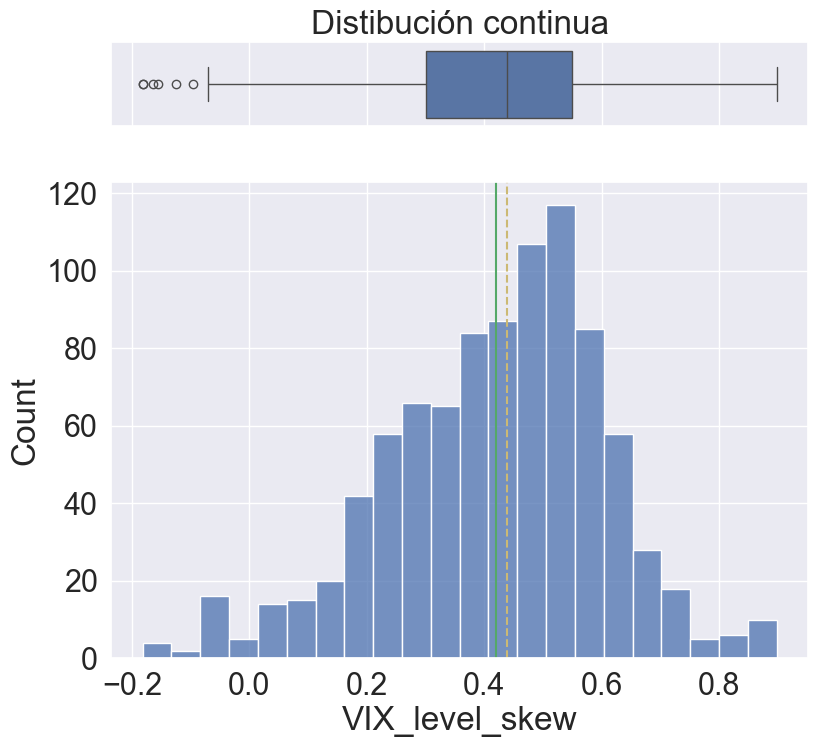

In [6]:
# Visualizar columna
col = 'VIX_level_skew'
pintar_columna(df_clean[col])

## Correlaciones

In [7]:
# Tabla de Correlaciones general
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
1114,AUDUSD_sma15_pct_diff_sma50_lag1,USDCAD_sma15_pct_diff_sma50_lag1,0.851418
5939,Gold_vol_directional_lag1_log,Gold_range15_position_lag1,0.806610
5374,GBPUSD_vol_directional_lag1_log,GBPUSD_range15_position_lag1,0.805208
5824,AUDUSD_vol_directional_lag1_log,AUDUSD_range15_position_lag1,0.802120
5264,EURUSD_vol_directional_lag1_log,EURUSD_range15_position_lag1,0.794146
567,USDCHF_acceleration_zscore_lag1,EURUSD_acceleration_zscore_lag1,0.781724
4847,USDCHF_std_lag1_log,EURUSD_std_lag1_log,0.778725
5485,USDJPY_vol_directional_lag1_log,USDJPY_range15_position_lag1,0.777394
792,USDCHF_sma15_pct_diff_sma50_lag1,EURUSD_sma15_pct_diff_sma50_lag1,0.769992
4945,AUDUSD_std_lag1_log,EURUSD_std_lag1_log,0.768972


* `vol_directional` y `range_position`: la precision del modelo disminuye al quitar la variable menos significativa de ellas. Por lo tanto se mantienen ambas variables a pesar de su alta correlacion.

## Análisis de Relaciones con la Variable Objetivo

### Correlaciones con la variable objetivo contínua

In [8]:
objetivo = f"{simbolo_objetivo}_intra_weekly"

top_correlaciones_objetivo(df=df_clean, target_col=objetivo)

,Variable,Correlación
0,GBPUSD_intra_weekly,0.646074
1,USDCHF_intra_weekly,-0.634386
2,AUDUSD_intra_weekly,0.468319
3,USDJPY_intra_weekly,-0.352379
4,USDCAD_intra_weekly,-0.346574
5,EURUSD_range15_position_lag1,-0.195043
6,USDCHF_return_zscore_lag1,0.177088
7,EURUSD_vol_directional_lag1_log,0.167264
8,USDCHF_range15_position_lag1,0.163651
9,DXY_vel_50d,0.156402


### Crear variable categórica

In [9]:
# Filtrar pares restantes
df_filtrado = filtrar_pares_restantes(df_clean,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df_filtrado.index.max()
df_train, df_live = separar_train_test(df=df_filtrado, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles

objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )

print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -3.152512     -0.502981
1          2     -0.502981      0.442246
2          3      0.442246      3.688076


In [10]:
# Separar predictores y var objetivo, que se convierte a tipo 'category'
X = df_train.drop(objetivo_cat, axis=1)
y = df_train[objetivo_cat].astype('category')

# Verificar frecuencia de clases
y.value_counts()

EURUSD_intra_weekly_cat
1    304
3    304
2    303
Name: count, dtype: int64

### Ranking de variables (V de Cramer)

In [11]:
_ = rankear_variables(X=X, y=y, percentil=50, graficar=True)

### Gráficos de violines

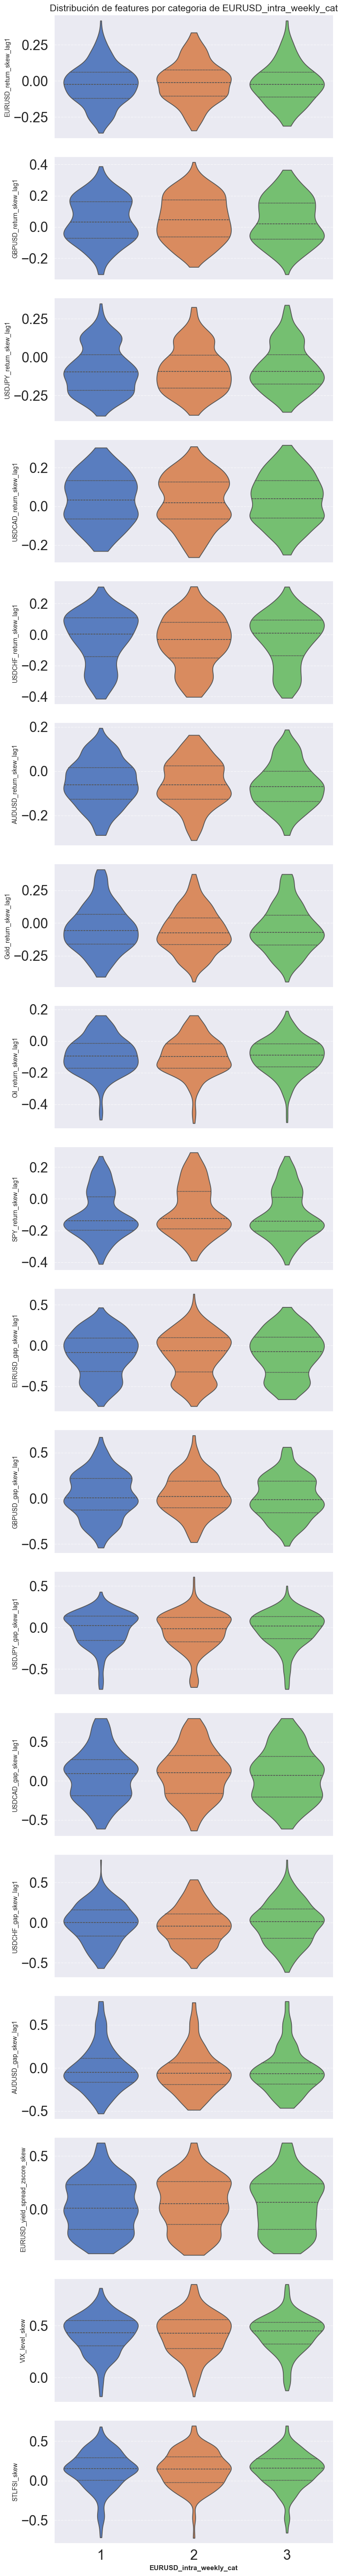

In [12]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

# Filtrar predictores
cadena = "_skew"
columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

pintar_violin_plots(
    df=df_train,
    numeric_cols=columnas,
    target_col=target_col
)